# Knowing When Not to Answer



In [1]:
!pip -q install "datasets<4" "transformers>=4.44" accelerate sentence-transformers

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
pathos 0.3.5 requires dill>=0.4.1, but you have dill 0.3.8 which is incompatible.
pathos 0.3.5 requires multiprocess>=0.70.19, but you have multiprocess 0.70.16 which is incompatible.
s3fs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [2]:
import os, re, json, time, math, random, pickle, warnings
import numpy as np, pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix
warnings.filterwarnings("ignore")

class CFG:
    QUICK_RUN = False                
    SEED = 42
    LANGUAGES = ["english", "hindi", "bengali", "telugu", "arabic", "chinese"]
    N_TRAIN, N_CAL, N_TEST = 100, 40, 60
    K = 5                            
    MAX_WORDS, MAX_CHARS = 60, 450   
    LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
    CLF_NAME = "xlm-roberta-base"
    RETRIEVER_NAME = "intfloat/multilingual-e5-small"
    CLF_EPOCHS, CLF_LR, CLF_BS, CLF_MAXLEN = 6, 3e-5, 8, 512
    USE_JUDGE = True                 
    TARGET_HALLUCINATION = 0.10      
    RUN_RETRIEVER_EXPERIMENT = True
    SUFFICIENT_CONTEXT_PATH = None   
    OUT_DIR = "/kaggle/working/outputs" if os.path.isdir("/kaggle/working") else "outputs"

if CFG.QUICK_RUN:
    CFG.LANGUAGES = ["english", "hindi"]
    CFG.N_TRAIN, CFG.N_CAL, CFG.N_TEST = 30, 10, 20
    CFG.CLF_EPOCHS = 2

os.makedirs(CFG.OUT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all(CFG.SEED)
rng = random.Random(CFG.SEED)
print("device:", DEVICE)

SUF, INS, IRR = 0, 1, 2
LABELS = ["SUFFICIENT", "RELEVANT_BUT_INSUFFICIENT", "IRRELEVANT"]

def cached(tag, fn):
    path = os.path.join(CFG.OUT_DIR, f"cache_{tag}.pkl")
    if os.path.exists(path):
        print("loaded cache:", path); return pickle.load(open(path, "rb"))
    out = fn(); pickle.dump(out, open(path, "wb")); return out

device: cuda


## 1. Data

3 classes:

- sufficient
- relevant but insufficient
- irrelevant



In [3]:
def trunc(t):
    t = " ".join((t or "").split()[:CFG.MAX_WORDS])
    return t[:CFG.MAX_CHARS]

def clean_passage(p):
    title = (p.get("title") or "").strip()
    text = (p.get("text") or "").strip()
    return {"docid": str(p.get("docid", "")), "text": trunc(f"{title}: {text}" if title else text)}

def load_nomiracl_split(language, split, subset):
    from datasets import load_dataset
    name = f"{split}.{subset}"
    try:
        ds = load_dataset("miracl/nomiracl", language, split=name, trust_remote_code=True)
    except TypeError:
        ds = load_dataset("miracl/nomiracl", language, split=name)
    return [dict(r) for r in ds]

def mk_item(lang, split, label, r, ctx, pos, pool):
    return dict(id=f"{lang}-{split}-{label}-{r['query_id']}", lang=lang, query=r["query"], label=label,
                passages=ctx, pos_texts=[p["text"] for p in pos], pos_ids=[p["docid"] for p in pos], pool=pool)

def build_items(language, split, n_per_class, rng):
    rel = [r for r in load_nomiracl_split(language, split, "relevant") if r["positive_passages"]]
    non = load_nomiracl_split(language, split, "non_relevant")
    rng.shuffle(rel); rng.shuffle(non)
    n = min(n_per_class, len(rel), len(non) // 2)
    items = []
    for r in rel[:n]:  # sufficient
        pos = [clean_passage(p) for p in r["positive_passages"]]
        neg = [clean_passage(p) for p in r["negative_passages"]]
        ctx = (pos[:2] + neg)[:CFG.K]; rng.shuffle(ctx)
        items.append(mk_item(language, split, SUF, r, ctx, pos[:2], pos + neg))
    ins_q, irr_q = non[:n], non[n:2 * n]
    for r in ins_q:  # relevant but insufficient
        neg = [clean_passage(p) for p in r["negative_passages"]]
        items.append(mk_item(language, split, INS, r, neg[:CFG.K], [], neg))
    for i, r in enumerate(irr_q):  # irrelevant: context from another query
        donor = irr_q[(i + 1) % len(irr_q)]
        own = [clean_passage(p) for p in r["negative_passages"]]
        dn = [clean_passage(p) for p in donor["negative_passages"]]
        items.append(mk_item(language, split, IRR, r, dn[:CFG.K], [], own))
    return items

def synthetic_items(n_per_class, rng, split, lang="english"):
    countries = [("France","Paris"),("Japan","Tokyo"),("Italy","Rome"),("Egypt","Cairo"),("Kenya","Nairobi"),
                 ("Peru","Lima"),("Norway","Oslo"),("Chile","Santiago"),("India","New Delhi"),("Spain","Madrid"),
                 ("Greece","Athens"),("Cuba","Havana")]
    filler = ["{c} has a population of several million people.", "The cuisine of {c} is popular with tourists.",
              "{c} borders several neighbouring states.", "The economy of {c} relies on trade and services.",
              "{c} hosts many festivals during the year.", "The climate of {c} varies across regions."]
    def ps(c, k, extra=None):
        t = [{"docid": f"{c}-{i}", "text": f.format(c=c)} for i, f in enumerate(rng.sample(filler, k))]
        return ([extra] if extra else []) + t
    items = []
    for i in range(n_per_class):
        c, cap = countries[i % len(countries)]; r = {"query_id": f"{split}{i}", "query": f"What is the capital of {c}?"}
        pos = {"docid": f"{c}-pos", "text": f"The capital of {c} is {cap}."}
        ctx = ps(c, CFG.K - 1, pos); rng.shuffle(ctx)
        items.append(mk_item(lang, split, SUF, r, ctx, [pos], ctx))
        r2 = {"query_id": f"{split}{i}i", "query": f"What is the capital of {c}?"}
        items.append(mk_item(lang, split, INS, r2, ps(c, CFG.K), [], ps(c, CFG.K)))
        o, _ = countries[(i + 5) % len(countries)]
        r3 = {"query_id": f"{split}{i}r", "query": f"What is the capital of {c}?"}
        items.append(mk_item(lang, split, IRR, r3, ps(o, CFG.K), [], ps(c, CFG.K)))
    return items

def split_stratified(items, frac_first, rng):
    groups = {}
    for it in items: groups.setdefault((it["lang"], it["label"]), []).append(it)
    a, b = [], []
    for v in groups.values():
        rng.shuffle(v); c = int(round(len(v) * frac_first)); a += v[:c]; b += v[c:]
    return a, b

USING_SYNTHETIC = False
dev_items, test_items = [], []
for lang in CFG.LANGUAGES:
    try:
        d = build_items(lang, "dev", CFG.N_TRAIN + CFG.N_CAL, rng)
        t = build_items(lang, "test", CFG.N_TEST, rng)
        dev_items += d; test_items += t
    except Exception as e:
        print(f"[{lang}] could not load NoMIRACL: {type(e).__name__}: {str(e)[:150]}")
if not test_items:
    print("\n>>> Falling back to SYNTHETIC data (plumbing check only; results are meaningless) <<<")
    USING_SYNTHETIC = True
    dev_items = synthetic_items(CFG.N_TRAIN + CFG.N_CAL, rng, "dev")
    test_items = synthetic_items(CFG.N_TEST, rng, "test")

frac = CFG.N_TRAIN / (CFG.N_TRAIN + CFG.N_CAL)
train_items, cal_items = split_stratified(dev_items, frac, rng)
for name, its in [("train", train_items), ("cal", cal_items), ("test", test_items)]:
    print(name, len(its), pd.Series([LABELS[i["label"]] for i in its]).value_counts().to_dict())

README.md:   0%|          | 0.00/8.08k [00:00<?, ?B/s]

nomiracl.py:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

data/english/corpus.jsonl.gz: reconstructing file:   0%|          |  0.00B / 9.69MB            

data/english/corpus.jsonl.gz: downloading bytes:           |  0.00B            

dev.relevant.tsv:   0%|          | 0.00/168k [00:00<?, ?B/s]

dev.non_relevant.tsv:   0%|          | 0.00/59.7k [00:00<?, ?B/s]

... (77 outputs left out)

Generating dev.non_relevant split: 0 examples [00:00, ? examples/s]

Generating test.relevant split: 0 examples [00:00, ? examples/s]

Generating test.non_relevant split: 0 examples [00:00, ? examples/s]

train 1731 {'SUFFICIENT': 577, 'RELEVANT_BUT_INSUFFICIENT': 577, 'IRRELEVANT': 577}
cal 696 {'SUFFICIENT': 232, 'RELEVANT_BUT_INSUFFICIENT': 232, 'IRRELEVANT': 232}
test 1080 {'SUFFICIENT': 360, 'RELEVANT_BUT_INSUFFICIENT': 360, 'IRRELEVANT': 360}


## 2. Models and prompts

In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification
from sentence_transformers import SentenceTransformer

class LLM:
    def __init__(self, name):
        self.tok = AutoTokenizer.from_pretrained(name)
        dtype = torch.float16 if DEVICE == "cuda" else torch.float32
        self.model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=dtype).to(DEVICE).eval()
    def _prompt(self, user):
        msgs = [{"role": "system", "content": "You are a careful, honest assistant."},
                {"role": "user", "content": user}]
        return self.tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    @torch.no_grad()
    def generate(self, user, max_new_tokens=64):
        ids = self.tok(self._prompt(user), return_tensors="pt").to(DEVICE)
        out = self.model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False,
                                  pad_token_id=self.tok.eos_token_id)
        return self.tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    @torch.no_grad()
    def option_probs(self, user, options):
        """Probability over the first token of each option (renormalised)."""
        ids = self.tok(self._prompt(user), return_tensors="pt").to(DEVICE)
        logits = self.model(**ids).logits[0, -1].float()
        tid = [self.tok.encode(o, add_special_tokens=False)[0] for o in options]
        return torch.softmax(logits[tid], -1).cpu().numpy()

llm = LLM(CFG.LLM_NAME)
retr = SentenceTransformer(CFG.RETRIEVER_NAME, device=DEVICE)

def ctx_block(passages): return "\n".join(f"[{i+1}] {p['text']}" for i, p in enumerate(passages))

P_STD = """Answer the question using the context below. Reply briefly, in the language of the question.

Context:
{ctx}

Question: {q}
Answer:"""

P_ABS = """Answer the question using ONLY the context below. If the context does not contain enough information to answer the question definitively, reply exactly: I don't know
Otherwise reply briefly, in the language of the question.

Context:
{ctx}

Question: {q}
Answer:"""

P_3WAY = """You are judging retrieved evidence for a question.

Context:
{ctx}

Question: {q}

Classify the context:
A) SUFFICIENT - it contains enough information to answer the question definitively.
B) RELEVANT BUT INSUFFICIENT - it is on-topic but lacks the information needed for a definitive answer.
C) IRRELEVANT - it contains no useful information for this question.

Respond with a single letter: A, B or C."""

P_YN = """Context:
{ctx}

Question: {q}

Does the context contain enough information to answer the question definitively? Respond with Yes or No."""

P_JUDGE = """Reference passages (verified relevant to the question):
{pos}

Question: {q}
Candidate answer: {a}

Is the candidate answer correct and supported by the reference passages? Respond with Yes or No."""

ABSTAIN_PAT = re.compile(r"(i don'?t know|i do not know|cannot (be )?answer|can'?t answer|not enough information|"
                         r"insufficient|no information|unable to (answer|determine)|does not (contain|provide))", re.I)
def is_abstain(text): return bool(ABSTAIN_PAT.search(text[:200]))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (14 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

## 3. Sufficiency signals

In [5]:
def retrieval_conf(items):
    qs = retr.encode(["query: " + it["query"] for it in items], normalize_embeddings=True, batch_size=64)
    flat, idx = [], []
    for i, it in enumerate(items):
        for p in it["passages"]:
            flat.append("passage: " + p["text"]); idx.append(i)
    ps = retr.encode(flat, normalize_embeddings=True, batch_size=64)
    idx = np.array(idx)
    sims = (ps * qs[idx]).sum(1)
    return pd.Series(sims).groupby(idx).max().reindex(range(len(items))).values

def llm_signals(items, desc="LLM signals"):
    rows = []
    for it in tqdm(items, desc=desc):
        ctx = ctx_block(it["passages"])
        p3 = llm.option_probs(P_3WAY.format(ctx=ctx, q=it["query"]), ["A", "B", "C"])
        yn = llm.option_probs(P_YN.format(ctx=ctx, q=it["query"]), ["Yes", "No"])
        rows.append(dict(pA=p3[0], pB=p3[1], pC=p3[2], C=yn[0]))
    return pd.DataFrame(rows)

def featurize(items, desc=""):
    base = pd.DataFrame({"id": [i["id"] for i in items], "lang": [i["lang"] for i in items],
                         "label": [i["label"] for i in items]})
    base["R_raw"] = retrieval_conf(items)
    return pd.concat([base, llm_signals(items, desc)], axis=1)

cal_df  = cached("cal_feat",  lambda: featurize(cal_items, "cal"))
test_df = cached("test_feat", lambda: featurize(test_items, "test"))
cal_df.head()

cal:   0%|          | 0/696 [00:00<?, ?it/s]

test:   0%|          | 0/1080 [00:00<?, ?it/s]

,id,lang,label,R_raw,pA,pB,pC,C
0,english-dev-0-517,english,0,0.899827,0.994380,0.005218,0.000402,0.974821
1,english-dev-0-1766,english,0,0.862628,0.950661,0.043774,0.005565,0.527317
2,english-dev-0-2860,english,0,0.904325,0.795009,0.201010,0.003981,0.290981
3,english-dev-0-2312,english,0,0.916779,0.990288,0.009410,0.000302,0.994270
4,english-dev-0-164,english,0,0.872579,0.981674,0.017701,0.000625,0.845942


## 4. Generate

In [6]:
def generate_all(items, df):
    std, ab, abst, ok_std, ok_abs = [], [], [], [], []
    for it in tqdm(items, desc="generate"):
        ctx, q = ctx_block(it["passages"]), it["query"]
        a1 = llm.generate(P_STD.format(ctx=ctx, q=q))
        a2 = llm.generate(P_ABS.format(ctx=ctx, q=q))
        ab_flag = is_abstain(a2)
        def judged(ans):
            if it["label"] != SUF: return False  # no sufficient context, so it can't be correct
            if not CFG.USE_JUDGE: return True
            pos = "\n".join(f"- {t}" for t in it["pos_texts"])
            return bool(llm.option_probs(P_JUDGE.format(pos=pos, q=q, a=ans[:300]), ["Yes", "No"])[0] > 0.5)
        std.append(a1); ab.append(a2); abst.append(ab_flag)
        ok_std.append(judged(a1)); ok_abs.append((not ab_flag) and judged(a2))
    out = df.copy()
    out["std_ans"], out["abs_ans"], out["abs_abstain"] = std, ab, abst
    out["ok_std"], out["ok_abs"] = ok_std, ok_abs
    return out

test_df = cached("test_gen", lambda: generate_all(test_items, test_df))
test_df[["lang", "label", "abs_abstain", "ok_std", "ok_abs"]].head()

generate:   0%|          | 0/1080 [00:00<?, ?it/s]

,lang,label,abs_abstain,ok_std,ok_abs
0,english,0,False,True,True
1,english,0,True,False,False
2,english,0,False,True,True
3,english,0,False,True,True
4,english,0,False,True,True


## 5. XLM-R on `question [SEP] passages`

In [7]:
class SufficiencyClassifier:
    def __init__(self, name, max_len):
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=3).to(DEVICE)
        self.max_len = max_len
    def _enc(self, items):
        a = [it["query"] for it in items]
        b = [" ".join(p["text"] for p in it["passages"]) for it in items]
        enc = self.tok(a, b, truncation="only_second", max_length=self.max_len, padding=True, return_tensors="pt")
        return {k: v.to(DEVICE) for k, v in enc.items()}
    def fit(self, items, epochs, lr, bs):
        from transformers import get_linear_schedule_with_warmup
        opt = torch.optim.AdamW(self.model.parameters(), lr=lr, weight_decay=0.01)
        steps = epochs * math.ceil(len(items) / bs)
        sch = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
        amp = DEVICE == "cuda"
        scaler = torch.cuda.amp.GradScaler(enabled=amp)
        for ep in range(epochs):
            self.model.train(); order = np.random.permutation(len(items)); tot = 0.0
            for i in tqdm(range(0, len(items), bs), desc=f"clf epoch {ep+1}/{epochs}"):
                batch = [items[j] for j in order[i:i + bs]]
                enc = self._enc(batch)
                y = torch.tensor([b["label"] for b in batch], device=DEVICE)
                with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                    loss = self.model(**enc, labels=y).loss
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sch.step(); opt.zero_grad()
                tot += loss.item() * len(batch)
            print(f"epoch {ep+1}: train loss {tot/len(items):.4f}")
    @torch.no_grad()
    def predict_proba(self, items, bs=16):
        self.model.eval(); out = []
        for i in range(0, len(items), bs):
            out.append(torch.softmax(self.model(**self._enc(items[i:i + bs])).logits.float(), -1).cpu().numpy())
        return np.concatenate(out)


def train_clf(name):
    c = SufficiencyClassifier(name, CFG.CLF_MAXLEN)
    c.fit(train_items, CFG.CLF_EPOCHS, CFG.CLF_LR, CFG.CLF_BS)
    pr = c.predict_proba(cal_items).argmax(1)
    y = np.array([i["label"] for i in cal_items])
    acc, n_classes = (pr == y).mean(), len(set(pr))
    print(f"{name}: cal accuracy={acc:.2f} (chance=0.33), distinct classes predicted={n_classes}")
    return c, acc, n_classes


clf, acc, n_classes = train_clf(CFG.CLF_NAME)
if n_classes < 2 or acc < 0.5:
    print("Classifier collapsed. Retrying with bert-base-multilingual-cased...")
    del clf
    torch.cuda.empty_cache()
    clf, acc, n_classes = train_clf("bert-base-multilingual-cased")


def add_clf(df, items):
    pr = clf.predict_proba(items)
    df = df.copy(); df["cS"], df["cI"], df["cR"] = pr[:, 0], pr[:, 1], pr[:, 2]; df["L"] = df["cS"]
    return df


cal_df, test_df = add_clf(cal_df, cal_items), add_clf(test_df, test_items)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

... (33 outputs left out)

epoch 6: train loss 0.0118
bert-base-multilingual-cased: cal accuracy=0.82 (chance=0.33), distinct classes predicted=3


epoch 4: train loss 0.4651


epoch 5: train loss 0.3211


epoch 6: train loss 0.1809
xlm-roberta-base: cal accuracy=0.82 (chance=0.33), distinct classes predicted=3


## 6. Combined score

S = aR + bC + gL answer if S >= tau

In [8]:
def fit_scaler(x): return tuple(np.percentile(x, [5, 95]))
def apply_scaler(x, lo, hi): return np.clip((np.asarray(x) - lo) / (hi - lo + 1e-9), 0, 1)

def add_scores(df, P):
    df = df.copy()
    df["R"] = apply_scaler(df["R_raw"], *P["R_scaler"])
    a, b, g = P["weights"]
    df["S"] = a * df["R"] + b * df["C"] + g * df["L"]
    df["P3"] = df["pA"]
    return df

def fit_weights(df, y, step=0.1):
    best = (-1, None)
    for a in np.arange(0, 1 + 1e-9, step):
        for b in np.arange(0, 1 - a + 1e-9, step):
            g = 1 - a - b
            auc = roc_auc_score(y, a * df["R"] + b * df["C"] + g * df["L"])
            if auc > best[0] + 1e-12: best = (auc, (float(round(a, 2)), float(round(b, 2)), float(round(g, 2))))
    return best

def youden_tau(y, s):
    fpr, tpr, thr = roc_curve(y, s); k = np.argmax(tpr - fpr); return float(thr[k])

def tau_for_target_hallucination(y, s, target):
    # smallest tau (most coverage) with hallucination rate <= target on the insufficient items
    cands = np.unique(s)
    ok = [t for t in cands if (s[~y] >= t).mean() <= target]
    return float(min(ok)) if ok else float(cands.max() + 1e-6)

P = {"R_scaler": fit_scaler(cal_df["R_raw"])}
cal_df = add_scores(cal_df, {**P, "weights": (1/3, 1/3, 1/3)})
y_cal = (cal_df["label"].values == SUF)
auc, W = fit_weights(cal_df, y_cal)
P["weights"] = W
cal_df, test_df = add_scores(cal_df, P), add_scores(test_df, P)
print(f"best calibration AUROC={auc:.3f}  weights (alpha, beta, gamma)={W}")

SIGNALS = {"Prompt 3-way P(A)": "P3", "Retrieval confidence (R)": "R", "LLM self-confidence (C)": "C",
           "Lightweight classifier (L)": "L", "Combined score (S)": "S"}
P["tau"] = {col: youden_tau(y_cal, cal_df[col].values) for col in SIGNALS.values()}
P["tau_S_target"] = tau_for_target_hallucination(y_cal, cal_df["S"].values, CFG.TARGET_HALLUCINATION)
print({k: round(v, 3) for k, v in P["tau"].items()}, "| tau_S@target:", round(P["tau_S_target"], 3))

best calibration AUROC=0.930  weights (alpha, beta, gamma)=(0.1, 0.1, 0.8)
{'P3': 0.438, 'R': 0.681, 'C': 0.535, 'L': 0.001, 'S': 0.168} | tau_S@target: 0.921


## 7. Metrics

In [9]:
def metrics(ans, label, correct):
    ans, correct = np.asarray(ans, bool), np.asarray(correct, bool)
    suf = np.asarray(label) == SUF
    na = ans.sum()
    return {"hallucination_rate": ans[~suf].mean() if (~suf).any() else np.nan,
            "error_rate": (~ans[suf]).mean() if suf.any() else np.nan,
            "coverage": ans.mean(),
            "answering_precision": (ans & suf).sum() / na if na else np.nan,
            "selective_accuracy": correct[ans].mean() if na else np.nan}

def method_decisions(df, P):
    n = len(df); ok = df["ok_std"].values
    M = {
        "1. Standard RAG (always answer)":       (np.ones(n, bool), ok),
        "2. Prompt abstention":                  (~df["abs_abstain"].values, df["ok_abs"].values),
        "3. Sufficiency: prompt 3-way (=A)":     (df[["pA", "pB", "pC"]].values.argmax(1) == 0, ok),
        "4a. Retrieval confidence (R)":          (df["R"].values >= P["tau"]["R"], ok),
        "4b. LLM self-confidence (C)":           (df["C"].values >= P["tau"]["C"], ok),
        "4c. Lightweight classifier (L)":        (df["L"].values >= P["tau"]["L"], ok),
        "5. Selective generation S (Youden τ)":  (df["S"].values >= P["tau"]["S"], ok),
        f"5. Selective generation S (τ @ ≤{int(CFG.TARGET_HALLUCINATION*100)}% halluc.)": (df["S"].values >= P["tau_S_target"], ok),
    }
    return M

def results_table(df, P):
    rows = {name: metrics(a, df["label"].values, c) for name, (a, c) in method_decisions(df, P).items()}
    return pd.DataFrame(rows).T

main_tbl = results_table(test_df, P)
display(main_tbl.style.format("{:.3f}").background_gradient(cmap="RdYlGn_r", subset=["hallucination_rate", "error_rate"])
        .background_gradient(cmap="RdYlGn", subset=["selective_accuracy", "answering_precision"]))
main_tbl.to_csv(f"{CFG.OUT_DIR}/main_results.csv")

y_test = (test_df["label"].values == SUF)
auc_tbl = pd.Series({n: roc_auc_score(y_test, test_df[c]) for n, c in SIGNALS.items()}, name="AUROC (sufficient vs not)")
display(auc_tbl.to_frame().style.format("{:.3f}"))

,hallucination_rate,error_rate,coverage,answering_precision,selective_accuracy
1. Standard RAG (always answer),1.000,0.000,1.000,0.333,0.147
2. Prompt abstention,0.151,0.408,0.298,0.661,0.360
3. Sufficiency: prompt 3-way (=A),0.247,0.181,0.438,0.624,0.304
4a. Retrieval confidence (R),0.251,0.197,0.435,0.615,0.296
4b. LLM self-confidence (C),0.217,0.194,0.413,0.650,0.309
4c. Lightweight classifier (L),0.246,0.183,0.436,0.624,0.289
5. Selective generation S (Youden τ),0.175,0.236,0.371,0.686,0.322
5. Selective generation S (τ @ ≤10% halluc.),0.078,0.447,0.236,0.780,0.404


,AUROC (sufficient vs not)
Prompt 3-way P(A),0.857
Retrieval confidence (R),0.864
LLM self-confidence (C),0.878
Lightweight classifier (L),0.870
Combined score (S),0.896


## 8. Threshold trade-off

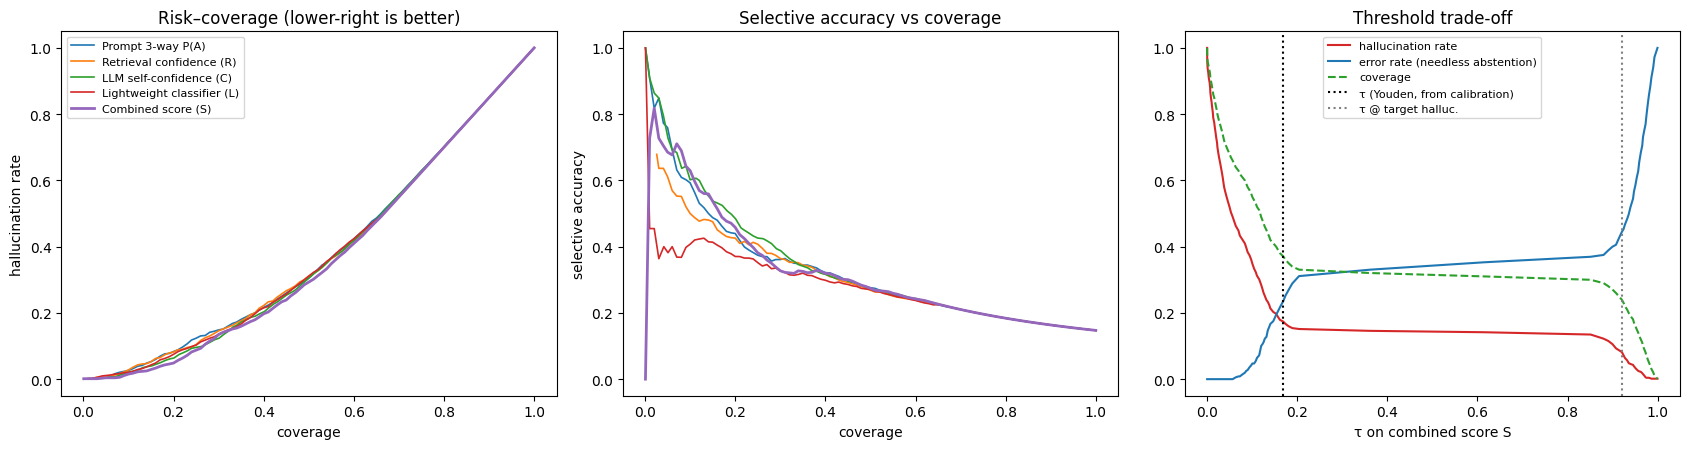

,"AURC (halluc. vs coverage, lower=better)"
Prompt 3-way P(A),0.380800
Retrieval confidence (R),0.378708
LLM self-confidence (C),0.373915
Lightweight classifier (L),0.376620
Combined score (S),0.368030


In [10]:
def sweep(score, label, correct, n_pts=101):
    thr = np.unique(np.quantile(score, np.linspace(0, 1, n_pts)))
    rows = []
    for t in thr:
        m = metrics(score >= t, label, correct); m["tau"] = t; rows.append(m)
    return pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for name, col in SIGNALS.items():
    sw = sweep(test_df[col].values, test_df["label"].values, test_df["ok_std"].values)
    ax[0].plot(sw["coverage"], sw["hallucination_rate"], label=name, lw=2 if col == "S" else 1.2)
    ax[1].plot(sw["coverage"], sw["selective_accuracy"], label=name, lw=2 if col == "S" else 1.2)
ax[0].set(xlabel="coverage", ylabel="hallucination rate", title="Risk–coverage (lower-right is better)")
ax[1].set(xlabel="coverage", ylabel="selective accuracy", title="Selective accuracy vs coverage")
ax[0].legend(fontsize=8)

swS = sweep(test_df["S"].values, test_df["label"].values, test_df["ok_std"].values)
ax[2].plot(swS["tau"], swS["hallucination_rate"], label="hallucination rate", c="tab:red")
ax[2].plot(swS["tau"], swS["error_rate"], label="error rate (needless abstention)", c="tab:blue")
ax[2].plot(swS["tau"], swS["coverage"], label="coverage", c="tab:green", ls="--")
ax[2].axvline(P["tau"]["S"], c="k", ls=":", label="τ (Youden, from calibration)")
ax[2].axvline(P["tau_S_target"], c="gray", ls=":", label="τ @ target halluc.")
ax[2].set(xlabel="τ on combined score S", title="Threshold trade-off"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/tradeoff.png", dpi=150); plt.show()

# area under the hallucination-vs-coverage curve (lower is better)
def aurc(df, col):
    sw = sweep(df[col].values, df["label"].values, df["ok_std"].values).sort_values("coverage")
    _trap = getattr(np, "trapezoid", None) or np.trapz
    return _trap(sw["hallucination_rate"].fillna(0), sw["coverage"])
display(pd.Series({n: aurc(test_df, c) for n, c in SIGNALS.items()}, name="AURC (halluc. vs coverage, lower=better)").to_frame())

## 9. Research questions:

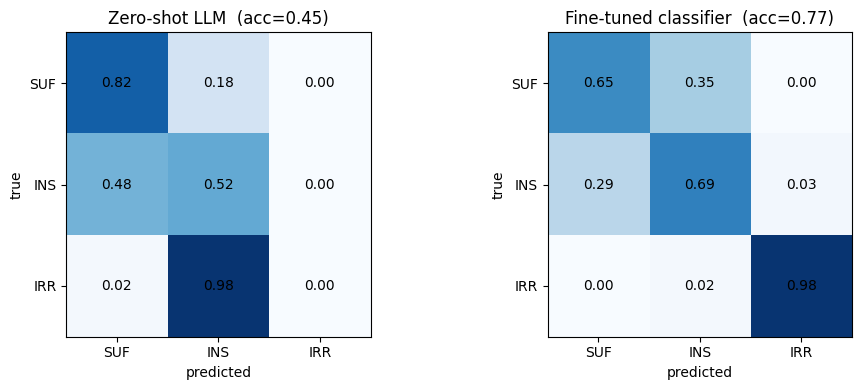

Zero-shot LLM
                            precision    recall  f1-score   support

               SUFFICIENT       0.62      0.82      0.71       360
RELEVANT_BUT_INSUFFICIENT       0.31      0.52      0.39       360
               IRRELEVANT       1.00      0.00      0.01       360

                 accuracy                           0.45      1080
                macro avg       0.64      0.45      0.37      1080
             weighted avg       0.64      0.45      0.37      1080

Classifier
                            precision    recall  f1-score   support

               SUFFICIENT       0.69      0.65      0.67       360
RELEVANT_BUT_INSUFFICIENT       0.65      0.69      0.67       360
               IRRELEVANT       0.98      0.98      0.98       360

                 accuracy                           0.77      1080
                macro avg       0.77      0.77      0.77      1080
             weighted avg       0.77      0.77      0.77      1080



In [11]:
y3 = test_df["label"].values
pred_llm = test_df[["pA", "pB", "pC"]].values.argmax(1)
pred_clf = test_df[["cS", "cI", "cR"]].values.argmax(1)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, pred, title in [(ax[0], pred_llm, "Zero-shot LLM"), (ax[1], pred_clf, "Fine-tuned classifier")]:
    cm = confusion_matrix(y3, pred, labels=[0, 1, 2], normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(range(3)); a.set_yticks(range(3))
    a.set_xticklabels(["SUF", "INS", "IRR"]); a.set_yticklabels(["SUF", "INS", "IRR"])
    a.set(title=f"{title}  (acc={np.mean(pred == y3):.2f})", xlabel="predicted", ylabel="true")
    for i in range(3):
        for j in range(3): a.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center")
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/confusion.png", dpi=150); plt.show()
print("Zero-shot LLM\n", classification_report(y3, pred_llm, labels=[0, 1, 2], target_names=LABELS, zero_division=0))
print("Classifier\n", classification_report(y3, pred_clf, labels=[0, 1, 2], target_names=LABELS, zero_division=0))

RQ2 and RQ3 are covered by the table in section 7 and the plots in section 8.

RQ4: cost of the classifier compared with LLM scoring.

In [12]:
sample = test_items[:min(30, len(test_items))]
t0 = time.time(); clf.predict_proba(sample); t_clf = (time.time() - t0) / len(sample)
t0 = time.time()
for it in sample: llm.option_probs(P_3WAY.format(ctx=ctx_block(it["passages"]), q=it["query"]), ["A", "B", "C"])
t_llm = (time.time() - t0) / len(sample)
n_clf = sum(p.numel() for p in clf.model.parameters()) / 1e6
n_llm = sum(p.numel() for p in llm.model.parameters()) / 1e6
print(pd.DataFrame({"params (M)": [n_clf, n_llm], "sec / item": [t_clf, t_llm]}, index=["Classifier (L)", "LLM scoring (C / 3-way)"]).round(4))

                         params (M)  sec / item
Classifier (L)             177.8557      0.0278
LLM scoring (C / 3-way)   1543.7143      0.1445


RQ5: per-language results.

In [13]:
key = ["1. Standard RAG (always answer)", "2. Prompt abstention", "4c. Lightweight classifier (L)",
       "5. Selective generation S (Youden τ)"]
per_lang = []
for lang, g in test_df.groupby("lang"):
    g = g.reset_index(drop=True)
    tbl = results_table(g, P).loc[key]; tbl.insert(0, "lang", lang); tbl.insert(0, "method", tbl.index)
    per_lang.append(tbl.reset_index(drop=True))
per_lang = pd.concat(per_lang)
per_lang.to_csv(f"{CFG.OUT_DIR}/per_language.csv", index=False)
for m in ["hallucination_rate", "error_rate", "coverage", "selective_accuracy"]:
    print(f"\n== {m} =="); display(per_lang.pivot(index="method", columns="lang", values=m).loc[key].style.format("{:.3f}"))


== hallucination_rate ==


lang,arabic,bengali,chinese,english,hindi,telugu
method,,,,,,
1. Standard RAG (always answer),1.000,1.000,1.000,1.000,1.000,1.000
2. Prompt abstention,0.225,0.083,0.250,0.183,0.108,0.058
4c. Lightweight classifier (L),0.233,0.217,0.283,0.358,0.233,0.150
5. Selective generation S (Youden τ),0.133,0.167,0.225,0.225,0.142,0.158



== error_rate ==


lang,arabic,bengali,chinese,english,hindi,telugu
method,,,,,,
1. Standard RAG (always answer),0.000,0.000,0.000,0.000,0.000,0.000
2. Prompt abstention,0.217,0.683,0.117,0.250,0.517,0.667
4c. Lightweight classifier (L),0.167,0.167,0.067,0.100,0.167,0.433
5. Selective generation S (Youden τ),0.200,0.217,0.050,0.233,0.300,0.417



== coverage ==


lang,arabic,bengali,chinese,english,hindi,telugu
method,,,,,,
1. Standard RAG (always answer),1.000,1.000,1.000,1.000,1.000,1.000
2. Prompt abstention,0.411,0.161,0.461,0.372,0.233,0.150
4c. Lightweight classifier (L),0.433,0.422,0.500,0.539,0.433,0.289
5. Selective generation S (Youden τ),0.356,0.372,0.467,0.406,0.328,0.300



== selective_accuracy ==


lang,arabic,bengali,chinese,english,hindi,telugu
method,,,,,,
1. Standard RAG (always answer),0.139,0.117,0.211,0.256,0.094,0.067
2. Prompt abstention,0.284,0.345,0.410,0.552,0.262,0.111
4c. Lightweight classifier (L),0.269,0.224,0.400,0.423,0.192,0.115
5. Selective generation S (Youden τ),0.328,0.254,0.452,0.493,0.169,0.130


## 10. Real retriever

In [14]:
def build_retrieved_items(items):
    out = []
    for lang in sorted({it["lang"] for it in items}):
        its = [it for it in items if it["lang"] == lang and it["label"] in (SUF, INS)]
        corpus = {}
        for it in its:
            for p in it["pool"]: corpus[p["docid"]] = p["text"]
        ids = list(corpus)
        emb = retr.encode(["passage: " + corpus[i] for i in ids], normalize_embeddings=True, batch_size=64)
        qe = retr.encode(["query: " + it["query"] for it in its], normalize_embeddings=True, batch_size=64)
        sims = qe @ emb.T
        for i, it in enumerate(its):
            top = np.argsort(-sims[i])[:CFG.K]
            ctx = [{"docid": ids[j], "text": corpus[ids[j]]} for j in top]
            hit = any(c["docid"] in set(it["pos_ids"]) for c in ctx)
            new = dict(it); new.update(passages=ctx, label=SUF if hit else INS, id=it["id"] + "-ret")
            out.append(new)
    return out

if CFG.RUN_RETRIEVER_EXPERIMENT:
    ret_items = build_retrieved_items(test_items)
    ret_df = featurize(ret_items, "retrieved")
    ret_df = add_clf(ret_df, ret_items)
    ret_df = add_scores(ret_df, P)
    ret_df = generate_all(ret_items, ret_df)
    print("retrieved-context label mix:", ret_df["label"].map(dict(enumerate(LABELS))).value_counts().to_dict())
    ret_tbl = results_table(ret_df, P)
    display(ret_tbl.style.format("{:.3f}"))
    ret_tbl.to_csv(f"{CFG.OUT_DIR}/retriever_results.csv")

retrieved:   0%|          | 0/720 [00:00<?, ?it/s]

generate:   0%|          | 0/720 [00:00<?, ?it/s]

retrieved-context label mix: {'RELEVANT_BUT_INSUFFICIENT': 397, 'SUFFICIENT': 323}


,hallucination_rate,error_rate,coverage,answering_precision,selective_accuracy
1. Standard RAG (always answer),1.000,0.000,1.000,0.449,0.217
2. Prompt abstention,0.360,0.378,0.478,0.584,0.326
3. Sufficiency: prompt 3-way (=A),0.587,0.130,0.714,0.547,0.282
4a. Retrieval confidence (R),0.582,0.142,0.706,0.545,0.280
4b. LLM self-confidence (C),0.504,0.149,0.660,0.579,0.305
4c. Lightweight classifier (L),0.645,0.090,0.764,0.535,0.264
5. Selective generation S (Youden τ),0.531,0.130,0.683,0.571,0.287
5. Selective generation S (τ @ ≤10% halluc.),0.287,0.282,0.481,0.671,0.358


## 11. Sufficient Context

In [15]:
def load_sufficient_context(path, limit=500):
    df = pd.read_json(path, lines=True) if path.endswith(".jsonl") else pd.read_csv(path)
    df = df.sample(min(limit, len(df)), random_state=CFG.SEED)
    items = []
    for i, r in enumerate(df.itertuples()):
        text = trunc(str(r.context)) if len(str(r.context)) < 4 * CFG.MAX_CHARS else str(r.context)[:CFG.MAX_CHARS * 3]
        items.append(dict(id=f"sc-{i}", lang="english", query=str(r.question), passages=[{"docid": f"sc{i}", "text": text}],
                          label=SUF if bool(r.sufficient) else INS, pos_texts=[text] if bool(r.sufficient) else [], pos_ids=[], pool=[]))
    return items

if CFG.SUFFICIENT_CONTEXT_PATH:
    sc_items = load_sufficient_context(CFG.SUFFICIENT_CONTEXT_PATH)
    sc_df = add_scores(add_clf(featurize(sc_items, "sufficient-context"), sc_items), P)
    sc_df = generate_all(sc_items, sc_df)
    ysc = (sc_df["label"].values == SUF)
    display(pd.Series({n: roc_auc_score(ysc, sc_df[c]) for n, c in SIGNALS.items()}, name="AUROC on Sufficient Context").to_frame())
    display(results_table(sc_df, P).style.format("{:.3f}"))
else:
    print("Set CFG.SUFFICIENT_CONTEXT_PATH to run the secondary evaluation.")

Set CFG.SUFFICIENT_CONTEXT_PATH to run the secondary evaluation.


## 12. SufficiencyAwareRAG

In [16]:
class SufficiencyAwareRAG:
    def __init__(self, llm, retr, clf, P, tau=None):
        self.llm, self.retr, self.clf, self.P = llm, retr, clf, P
        self.tau = P["tau"]["S"] if tau is None else tau
    def score(self, question, passages):
        passages = [{"docid": str(i), "text": trunc(p)} for i, p in enumerate(passages)]
        item = {"query": question, "passages": passages, "label": SUF}
        R_raw = retrieval_conf([item])[0]
        ctx = ctx_block(passages)
        yn = self.llm.option_probs(P_YN.format(ctx=ctx, q=question), ["Yes", "No"])[0]
        p3 = self.llm.option_probs(P_3WAY.format(ctx=ctx, q=question), ["A", "B", "C"])
        L = float(self.clf.predict_proba([item])[0, 0])
        R = float(apply_scaler(R_raw, *self.P["R_scaler"]))
        a, b, g = self.P["weights"]
        return dict(R=R, C=float(yn), L=L, S=a * R + b * float(yn) + g * L,
                    llm_class=LABELS[int(np.argmax(p3))], passages=passages, ctx=ctx)
    def answer(self, question, passages):
        s = self.score(question, passages)
        if s["S"] >= self.tau:
            return {"decision": "ANSWER", "answer": self.llm.generate(P_STD.format(ctx=s["ctx"], q=question)),
                    **{k: s[k] for k in ("R", "C", "L", "S", "llm_class")}}
        return {"decision": "ABSTAIN", "answer": "I don't know: the retrieved evidence is insufficient.",
                **{k: s[k] for k in ("R", "C", "L", "S", "llm_class")}}

rag = SufficiencyAwareRAG(llm, retr, clf, P)
q = "Who won the Zephyr Prize for Literature in 2022?"
demo = {
  "insufficient (2021 & 2023 only)": ["The Zephyr Prize for Literature 2021 was awarded to Maria Ortega.",
                                      "In 2023 the Zephyr Prize for Literature went to Jon Akhtar.",
                                      "The Zephyr Prize is awarded annually in Lisbon."],
  "sufficient": ["The Zephyr Prize for Literature 2022 was awarded to Lena Hartmann for her novel 'Salt Roads'.",
                 "The Zephyr Prize is awarded annually in Lisbon."],
  "irrelevant": ["The mitochondria is the powerhouse of the cell.", "Photosynthesis converts light into chemical energy."],
}
for name, ps in demo.items():
    r = rag.answer(q, ps)
    print(f"[{name}] -> {r['decision']}  S={r['S']:.2f} (R={r['R']:.2f}, C={r['C']:.2f}, L={r['L']:.2f}, LLM says {r['llm_class']})\n   {r['answer']}\n")

[insufficient (2021 & 2023 only)] -> ANSWER  S=0.81 (R=0.77, C=0.01, L=0.92, LLM says RELEVANT_BUT_INSUFFICIENT)
   The information provided does not mention any winner for the Zephyr Prize for Literature in 2022. Therefore, we cannot determine who won that year based on the given context.

[sufficient] -> ANSWER  S=0.99 (R=0.88, C=1.00, L=1.00, LLM says SUFFICIENT)
   Lena Hartmann

[irrelevant] -> ABSTAIN  S=0.00 (R=0.00, C=0.00, L=0.00, LLM says RELEVANT_BUT_INSUFFICIENT)
   I don't know: the retrieved evidence is insufficient.



## outputs

In [17]:
json.dump({"weights": P["weights"], "tau": P["tau"], "tau_S_target": P["tau_S_target"],
           "R_scaler": [float(x) for x in P["R_scaler"]], "config": {k: v for k, v in vars(CFG).items() if k.isupper()}},
          open(f"{CFG.OUT_DIR}/params.json", "w"), indent=2, default=str)
test_df.drop(columns=["std_ans", "abs_ans"]).to_csv(f"{CFG.OUT_DIR}/test_scores.csv", index=False)
print("saved to", CFG.OUT_DIR, os.listdir(CFG.OUT_DIR))
if USING_SYNTHETIC: print("\n!! These results come from SYNTHETIC fallback data and are NOT meaningful. !!")

saved to /kaggle/working/outputs ['retriever_results.csv', 'tradeoff.png', 'main_results.csv', 'params.json', 'cache_test_gen.pkl', 'confusion.png', 'per_language.csv', 'cache_test_feat.pkl', 'test_scores.csv', 'cache_cal_feat.pkl']
